In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
df=pd.read_csv('salesdaily.csv')

In [4]:
df


,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,1/2/2014,0.00,3.670,3.40,32.40,7.0,0.0,0.0,2.00,2014,1,248,Thursday
1,1/3/2014,8.00,4.000,4.40,50.60,16.0,0.0,20.0,4.00,2014,1,276,Friday
2,1/4/2014,2.00,1.000,6.50,61.85,10.0,0.0,9.0,1.00,2014,1,276,Saturday
3,1/5/2014,4.00,3.000,7.00,41.10,8.0,0.0,3.0,0.00,2014,1,276,Sunday
4,1/6/2014,5.00,1.000,4.50,21.70,16.0,2.0,6.0,2.00,2014,1,276,Monday
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2101,10/4/2019,7.34,5.683,2.25,22.45,13.0,0.0,1.0,1.00,2019,10,276,Friday
2102,10/5/2019,3.84,5.010,6.00,25.40,7.0,0.0,0.0,0.33,2019,10,276,Saturday
2103,10/6/2019,4.00,11.690,2.00,34.60,6.0,0.0,5.0,4.20,2019,10,276,Sunday
2104,10/7/2019,7.34,4.507,3.00,50.80,6.0,0.0,10.0,1.00,2019,10,276,Monday


In [5]:
df.columns

Index(['datum', 'M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03',
       'R06', 'Year', 'Month', 'Hour', 'Weekday Name'],
      dtype='object')

In [6]:
df.shape

(2106, 13)

In [7]:
df.isnull().sum()

datum           0
M01AB           0
M01AE           0
N02BA           0
N02BE           0
N05B            0
N05C            0
R03             0
R06             0
Year            0
Month           0
Hour            0
Weekday Name    0
dtype: int64

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2106 entries, 0 to 2105
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   datum         2106 non-null   object 
 1   M01AB         2106 non-null   float64
 2   M01AE         2106 non-null   float64
 3   N02BA         2106 non-null   float64
 4   N02BE         2106 non-null   float64
 5   N05B          2106 non-null   float64
 6   N05C          2106 non-null   float64
 7   R03           2106 non-null   float64
 8   R06           2106 non-null   float64
 9   Year          2106 non-null   int64  
 10  Month         2106 non-null   int64  
 11  Hour          2106 non-null   int64  
 12  Weekday Name  2106 non-null   object 
dtypes: float64(8), int64(3), object(2)
memory usage: 214.0+ KB


In [9]:
df.describe()

,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour
count,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000
mean,5.033683,3.895830,3.880441,29.917095,8.853627,0.593522,5.512262,2.900198,2016.401235,6.344255,275.945869
std,2.737579,2.133337,2.384010,15.590966,5.605605,1.092988,6.428736,2.415816,1.665060,3.386954,1.970547
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2014.000000,1.000000,190.000000
25%,3.000000,2.340000,2.000000,19.000000,5.000000,0.000000,1.000000,1.000000,2015.000000,3.000000,276.000000
50%,4.990000,3.670000,3.500000,26.900000,8.000000,0.000000,4.000000,2.000000,2016.000000,6.000000,276.000000
75%,6.670000,5.138000,5.200000,38.300000,12.000000,1.000000,8.000000,4.000000,2018.000000,9.000000,276.000000
max,17.340000,14.463000,16.000000,161.000000,54.833333,9.000000,45.000000,15.000000,2019.000000,12.000000,276.000000


In [32]:
#What are the total sales quantities for each drug category (ATC code)?
df_drugs=['M01AB','M01AE',"N02BA",'N02BE',"N05B",'N05C','R03','R06']
total_sales=df[df_drugs].sum().sort_values(ascending=False)
total_sales

N02BE    63005.402708
N05B     18645.737500
R03      11608.822917
M01AB    10600.937083
M01AE     8204.618646
N02BA     8172.209000
R06       6107.817500
N05C      1249.958333
dtype: float64

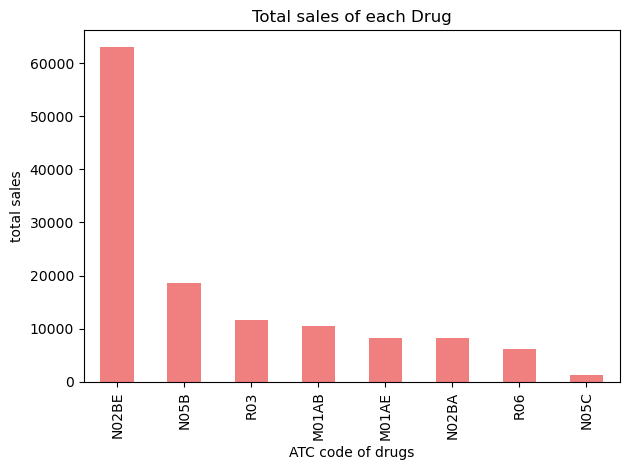

In [36]:
total_sales.plot(kind='bar',color='lightcoral')
plt.title("Total sales of each Drug")
plt.xlabel("ATC code of drugs")
plt.ylabel('total sales')
plt.tight_layout()
plt.show()

In [39]:
#Which individual drug brands have the highest total sales?
print(total_sales.index[0],"has highest total sales.")

N02BE has highest total sales


In [48]:
#Which three drugs have the highest sales in January 2015, July 2016, September 2017.
def get_top_3_monthly(year, month):
    subset = df[(df['Year'] == year) & (df['Month'] == month)]
    return subset[df_drugs].sum().sort_values(ascending=False).head(3)

print("\n3. Top 3 Drugs in specific periods:")
print(f"January 2015:\n{get_top_3_monthly(2015, 1)}")
print(f"\nJuly 2016:\n{get_top_3_monthly(2016, 7)}")
print(f"\nSeptember 2017:\n{get_top_3_monthly(2017, 9)}")



3. Top 3 Drugs in specific periods:
January 2015:
N02BE    1044.24
N05B      463.00
R03       177.25
dtype: float64

July 2016:
N02BE    652.362000
N05B     240.000000
M01AB    194.528333
dtype: float64

September 2017:
N02BE    863.75
N05B     223.00
R03      139.00
dtype: float64


In [59]:
#Which drug has sold the most often in 2017?
sales_2017=df[df['Year']==2017][df_drugs].sum().sort_values(ascending=False)

In [60]:
sales_2017

N02BE    9258.804833
N05B     2555.541667
R03      1893.614583
M01AB    1846.617083
M01AE    1387.298333
N02BA    1288.295833
R06       988.860000
N05C      180.333333
dtype: float64

In [62]:
print(sales_2017.index[0],"has been sold most often in 2017.")

N02BE has been sold most often in 2017


In [64]:
#Which drug category has the highest average daily sales?
avg_sales=df[df_drugs].mean().sort_values(ascending=False)
avg_sales


N02BE    29.917095
N05B      8.853627
R03       5.512262
M01AB     5.033683
M01AE     3.895830
N02BA     3.880441
R06       2.900198
N05C      0.593522
dtype: float64

In [65]:
print(avg_sales.index[0],'has highest average daily sales.')

N02BE has highest average daily sales.


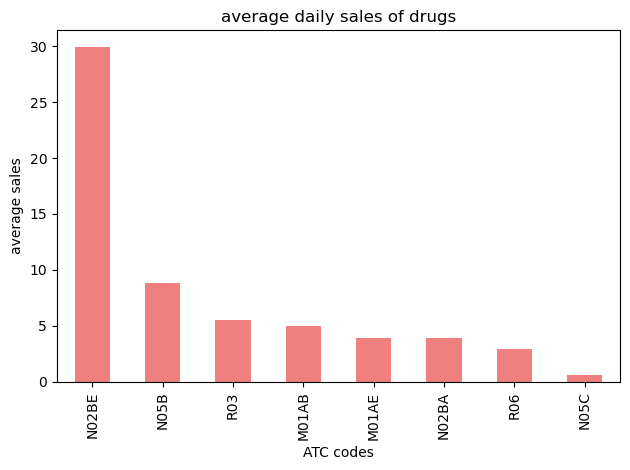

In [69]:
avg_sales.plot(kind='bar',color='lightcoral')
plt.title('average daily sales of drugs')
plt.ylabel('average sales')
plt.xlabel('ATC codes')
plt.tight_layout()
plt.show()

In [74]:
#Are respiratory drugs (R03) sold more during specific months?
r03_monthly = df.groupby('Month')['R03'].mean()
print("\n6. Monthly sales for Respiratory Drugs (R03):")
print(r03_monthly)


6. Monthly sales for Respiratory Drugs (R03):
Month
1     6.835980
2     6.896943
3     6.290323
4     5.771528
5     5.006944
6     4.350000
7     2.956989
8     3.102151
9     4.402315
10    7.208589
11    6.226667
12    7.916129
Name: R03, dtype: float64


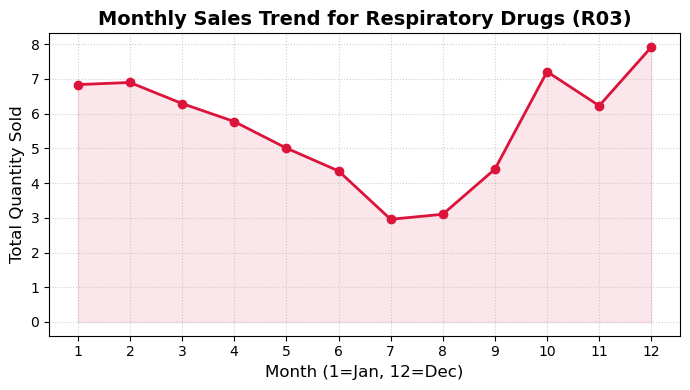

In [80]:
plt.figure(figsize=(7, 4))
plt.plot(r03_monthly.index, r03_monthly.values, marker='o', linestyle='-', color='crimson', linewidth=2)
plt.title('Monthly Sales Trend for Respiratory Drugs (R03)', fontsize=14, fontweight='bold')
plt.xlabel('Month (1=Jan, 12=Dec)', fontsize=12)
plt.ylabel('Total Quantity Sold', fontsize=12)
plt.xticks(range(1, 13))
plt.grid(True, linestyle=':', alpha=0.6)
plt.fill_between(r03_monthly.index, r03_monthly.values, color='crimson', alpha=0.1)
plt.tight_layout()
plt.show()

In [78]:
print('highest sales in month',r03_monthly.sort_values(ascending=False).index[0])
print('highest sales in month',r03_monthly.sort_values(ascending=False).index[-1])

highest sales in month 12
highest sales in month 7
